## Environment used
I use a **5x5 GridWorld** for all exercises.
- Start state: (0,0) (top-left corner)
- Goal state: (4,4) (bottom-right corner) -> big positive reward
- Two pits (traps): (1,3) and (3,1) -> big negative reward, episode ends
- Actions: Up, Down, Left, Right
- The floor is a little *slippery*: with probability 0.8 the agent moves in the chosen direction, and with probability 0.1 each it slips to one of the two sideways directions. Hitting the wall means the agent stays in the same cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

np.random.seed(42)
plt.rcParams['figure.dpi'] = 100

---
# Exercise 1: Markov Model

A Markov model says that the next state depends **only on the current state** (the Markov property):

P(S(t+1) | S(t), S(t-1), ...) = P(S(t+1) | S(t))

## 1(a) A simple example: weather Markov chain
First I start with a small 3-state chain (Sunny, Cloudy, Rainy) to understand long-term behavior.

In [2]:
states = ['Sunny', 'Cloudy', 'Rainy']
# rows = current state, columns = next state (each row sums to 1)
P_weather = np.array([
    [0.7, 0.2, 0.1],
    [0.3, 0.4, 0.3],
    [0.2, 0.3, 0.5],
])
print("Row sums:", P_weather.sum(axis=1))
print(pd.DataFrame(P_weather, index=states, columns=states))

Row sums: [1. 1. 1.]
        Sunny  Cloudy  Rainy
Sunny     0.7     0.2    0.1
Cloudy    0.3     0.4    0.3
Rainy     0.2     0.3    0.5


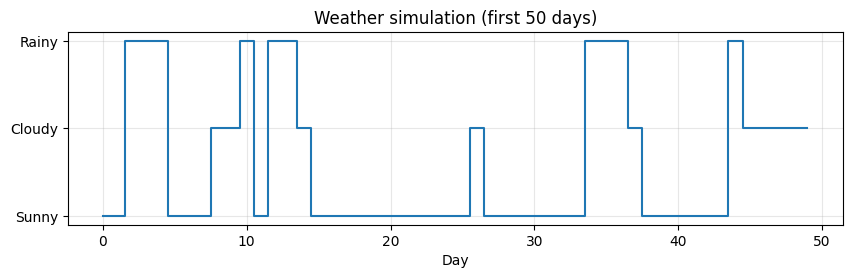

Simulated long-run fractions: {'Sunny': 0.472, 'Cloudy': 0.26, 'Rainy': 0.269}


In [3]:
# Simulate the weather for 1000 days
def simulate_chain(P, start, n_steps):
    path = [start]
    for _ in range(n_steps):
        path.append(np.random.choice(len(P), p=P[path[-1]]))
    return path

path = simulate_chain(P_weather, start=0, n_steps=1000)

# Visualize first 50 days
plt.figure(figsize=(10, 2.5))
plt.step(range(50), path[:50], where='mid')
plt.yticks([0, 1, 2], states)
plt.xlabel('Day'); plt.title('Weather simulation (first 50 days)')
plt.grid(alpha=0.3)
plt.show()

# Fraction of time spent in each state
counts = Counter(path)
freq = np.array([counts[i] for i in range(3)]) / len(path)
print("Simulated long-run fractions:", {k: round(float(v), 3) for k, v in zip(states, freq)})

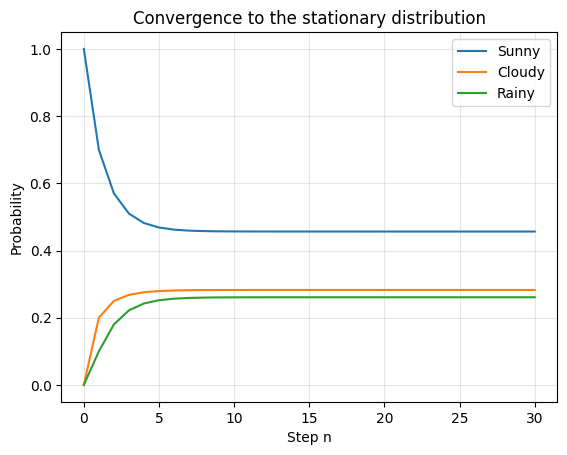

Stationary distribution (eigenvector): {'Sunny': 0.4565, 'Cloudy': 0.2826, 'Rainy': 0.2609}
Distribution after 30 steps          : {'Sunny': 0.4565, 'Cloudy': 0.2826, 'Rainy': 0.2609}


In [4]:
# Long-term behavior: distribution after n steps  pi_n = pi_0 * P^n
pi = np.array([1.0, 0.0, 0.0])   # start sunny for sure
history = [pi]
for n in range(30):
    pi = pi @ P_weather
    history.append(pi)
history = np.array(history)

for i, s in enumerate(states):
    plt.plot(history[:, i], label=s)
plt.xlabel('Step n'); plt.ylabel('Probability'); plt.legend()
plt.title('Convergence to the stationary distribution'); plt.grid(alpha=0.3)
plt.show()

# Stationary distribution = left eigenvector of P with eigenvalue 1
vals, vecs = np.linalg.eig(P_weather.T)
stat = np.real(vecs[:, np.argmin(abs(vals - 1))])
stat = stat / stat.sum()
print("Stationary distribution (eigenvector):", {k: round(float(v), 4) for k, v in zip(states, stat)})
print("Distribution after 30 steps          :", {k: round(float(v), 4) for k, v in zip(states, history[-1])})

## 1(b) Markov model of the GridWorld
Now I define the GridWorld. Each cell is a state. If the agent picks actions randomly, then the GridWorld is itself a Markov chain with a transition matrix. The goal and pits are *absorbing* states (once entered, the agent never leaves).

In [5]:
class GridWorld:
    ACTIONS = ['Up', 'Down', 'Left', 'Right']
    MOVES = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
    SIDEWAYS = {0: (2, 3), 1: (2, 3), 2: (0, 1), 3: (0, 1)}   # slip directions

    def __init__(self, size=5, goal=(4, 4), pits=((1, 3), (3, 1)), start=(0, 0),
                 slip=0.1, step_reward=-0.5, goal_reward=10.0, pit_reward=-10.0):
        self.size = size
        self.goal, self.pits, self.start = goal, list(pits), start
        self.slip = slip
        self.step_reward, self.goal_reward, self.pit_reward = step_reward, goal_reward, pit_reward
        self.n_states = size * size
        self.n_actions = 4
        self.terminals = [goal] + self.pits

    # state <-> index helpers
    def idx(self, s): return s[0] * self.size + s[1]
    def pos(self, i): return (i // self.size, i % self.size)
    def is_terminal(self, s): return s in self.terminals

    def _move(self, s, a):
        dr, dc = self.MOVES[a]
        r, c = s[0] + dr, s[1] + dc
        if 0 <= r < self.size and 0 <= c < self.size:
            return (r, c)
        return s                       # bumped into wall

    def reward(self, s_next):
        if s_next == self.goal: return self.goal_reward
        if s_next in self.pits: return self.pit_reward
        return self.step_reward

    def transitions(self, s, a):
        """list of (probability, next_state) for taking action a in state s"""
        if self.is_terminal(s):
            return [(1.0, s)]
        side1, side2 = self.SIDEWAYS[a]
        return [(1 - 2 * self.slip, self._move(s, a)),
                (self.slip, self._move(s, side1)),
                (self.slip, self._move(s, side2))]

    def reset(self):
        return self.start

    def step(self, s, a):
        probs, nxt = zip(*self.transitions(s, a))
        s_next = nxt[np.random.choice(len(nxt), p=probs)]
        return s_next, self.reward(s_next), self.is_terminal(s_next)

env = GridWorld()
print("Number of states:", env.n_states)
print("Transitions from (0,0) taking 'Right':", env.transitions((0, 0), 3))

Number of states: 25
Transitions from (0,0) taking 'Right': [(0.8, (0, 1)), (0.1, (0, 0)), (0.1, (1, 0))]


In [6]:
# Build the 25x25 transition matrix for a RANDOM policy (each action with prob 0.25)
def markov_matrix(env, policy=None):
    P = np.zeros((env.n_states, env.n_states))
    for i in range(env.n_states):
        s = env.pos(i)
        for a in range(env.n_actions):
            pa = 0.25 if policy is None else (1.0 if policy[i] == a else 0.0)
            for p, s2 in env.transitions(s, a):
                P[i, env.idx(s2)] += pa * p
    return P

P_grid = markov_matrix(env)
print("All rows sum to 1?", np.allclose(P_grid.sum(axis=1), 1))
print("Row for state (0,0):", P_grid[0].round(2))

All rows sum to 1? True
Row for state (0,0): [0.5  0.25 0.   0.   0.   0.25 0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]


Where did random walks end?
  (1, 3) (PIT): 47.1%
  (3, 1) (PIT): 47.1%
  (4, 4) (GOAL): 5.8%
Average episode length: 19.797622


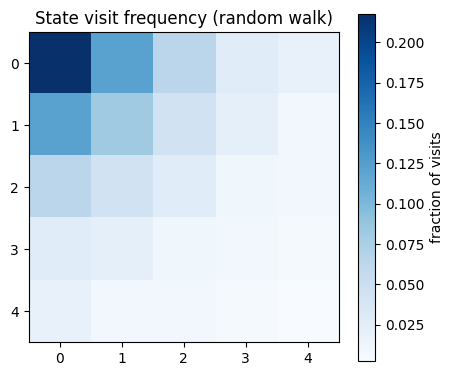

In [7]:
# Simulate many random-walk episodes and count where they end
def random_walk(env, max_steps=500):
    s = env.reset(); path = [s]
    for _ in range(max_steps):
        s, r, done = env.step(s, np.random.randint(4))
        path.append(s)
        if done: break
    return path

N = 500000
ends = Counter()
lengths = []
visits = np.zeros((env.size, env.size))
for _ in range(N):
    p = random_walk(env)
    ends[p[-1]] += 1
    lengths.append(len(p) - 1)
    for (r, c) in p: visits[r, c] += 1

print("Where did random walks end?")
for k, v in ends.items():
    name = 'GOAL' if k == env.goal else 'PIT'
    print(f"  {k} ({name}): {v/N*100:.1f}%")
print("Average episode length:", np.mean(lengths))

# Visualize visit frequency
plt.figure(figsize=(5, 4.5))
plt.imshow(visits / visits.sum(), cmap='Blues')
plt.colorbar(label='fraction of visits')
plt.title('State visit frequency (random walk)')
plt.xticks(range(5)); plt.yticks(range(5))
plt.show()

In [8]:
# Long-term behavior using absorbing Markov chain theory
terminal_idx = [env.idx(t) for t in env.terminals]
trans_idx = [i for i in range(env.n_states) if i not in terminal_idx]

Q = P_grid[np.ix_(trans_idx, trans_idx)]        # transient -> transient
R = P_grid[np.ix_(trans_idx, terminal_idx)]     # transient -> absorbing
Nmat = np.linalg.inv(np.eye(len(trans_idx)) - Q)  # fundamental matrix
B = Nmat @ R                                      # absorption probabilities
expected_steps = Nmat.sum(axis=1)

k = trans_idx.index(env.idx(env.start))
print("From the start state under a random policy:")
print(f"  P(reach goal)  = {B[k, 0]:.3f}")
print(f"  P(fall in pit) = {B[k, 1] + B[k, 2]:.3f}")
print(f"  Expected steps until absorbed = {expected_steps[k]:.1f}")
print("(compare with the simulation above)")

# Long-run distribution: P^n for large n
Pn = np.linalg.matrix_power(P_grid, 2000)
print("\nLong-run distribution starting from (0,0):")
for t in env.terminals:
    print(f"  {t}: {Pn[0, env.idx(t)]:.3f}")

From the start state under a random policy:
  P(reach goal)  = 0.058
  P(fall in pit) = 0.942
  Expected steps until absorbed = 19.8
(compare with the simulation above)

Long-run distribution starting from (0,0):
  (4, 4): 0.058
  (1, 3): 0.471
  (3, 1): 0.471


**Observation:** Because the goal and pits are absorbing, the long-term behavior is different from the weather chain: eventually the agent ends up in one of the 3 absorbing states with probability 1. The matrix calculation matches the simulation. A random agent often falls in a pit, so we need to *learn* a better policy.

---
# Exercise 2: Reward-Based Decision-Making


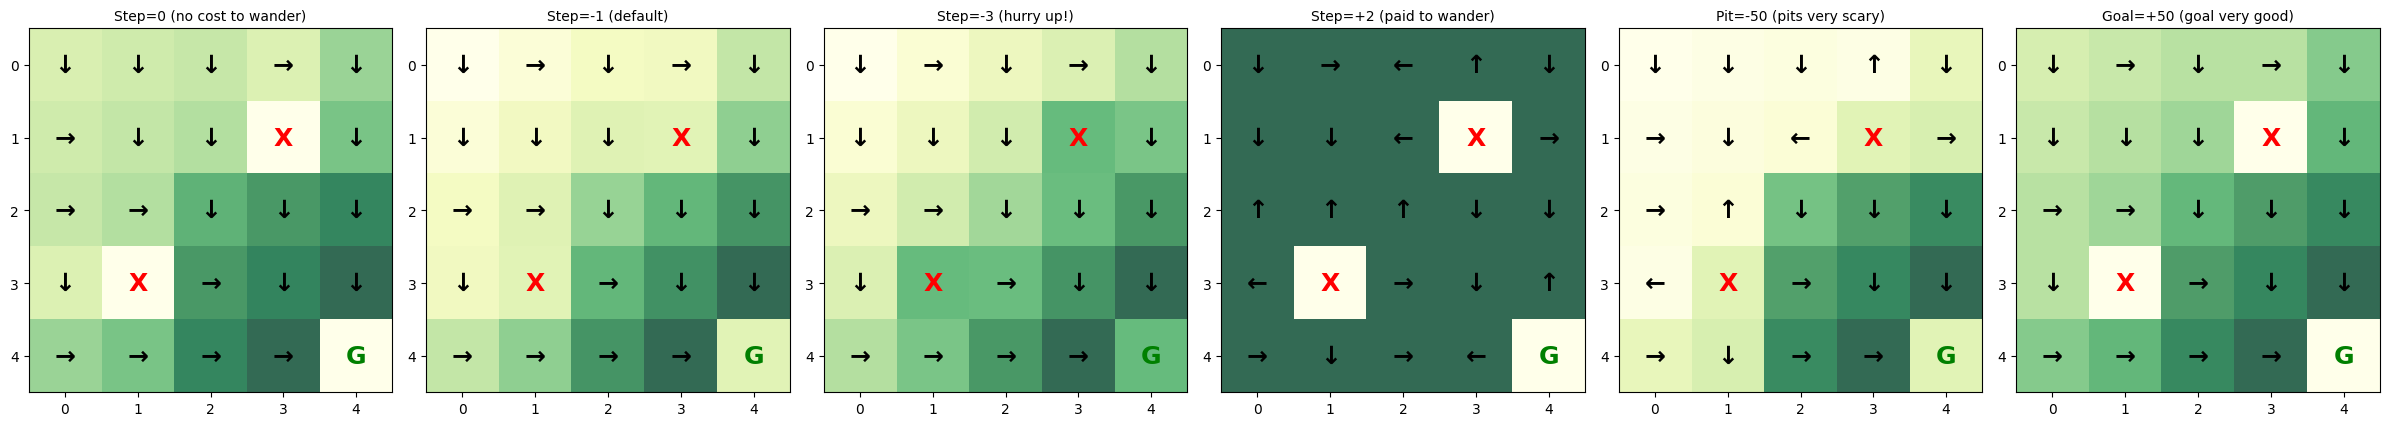

In [9]:
def value_iteration(env, gamma=0.9, theta=1e-6):
    V = np.zeros(env.n_states)
    while True:
        delta = 0
        for i in range(env.n_states):
            s = env.pos(i)
            if env.is_terminal(s): continue
            q = [sum(p * (env.reward(s2) + gamma * V[env.idx(s2)] * (not env.is_terminal(s2)))
                     for p, s2 in env.transitions(s, a)) for a in range(4)]
            new = max(q)
            delta = max(delta, abs(new - V[i])); V[i] = new
        if delta < theta: break
    # extract greedy policy
    policy = np.zeros(env.n_states, dtype=int)
    for i in range(env.n_states):
        s = env.pos(i)
        if env.is_terminal(s): continue
        q = [sum(p * (env.reward(s2) + gamma * V[env.idx(s2)] * (not env.is_terminal(s2)))
                 for p, s2 in env.transitions(s, a)) for a in range(4)]
        policy[i] = int(np.argmax(q))
    return V, policy

ARROWS = ['↑', '↓', '←', '→']

def show_policy(env, policy, values=None, title='', ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 4.5))
    grid = np.zeros((env.size, env.size))
    if values is not None:
        grid = values.reshape(env.size, env.size)
    ax.imshow(grid, cmap='YlGn' if values is not None else 'Greys', alpha=0.8 if values is not None else 0.1)
    for r in range(env.size):
        for c in range(env.size):
            s = (r, c)
            if s == env.goal: txt, col = 'G', 'green'
            elif s in env.pits: txt, col = 'X', 'red'
            else: txt, col = ARROWS[policy[env.idx(s)]], 'black'
            ax.text(c, r, txt, ha='center', va='center', fontsize=18, color=col, fontweight='bold')
    ax.set_xticks(range(env.size)); ax.set_yticks(range(env.size))
    ax.set_title(title, fontsize=10)

settings = {
    'Step=0 (no cost to wander)':   dict(step_reward=0.0),
    'Step=-1 (default)':            dict(step_reward=-1.0),
    'Step=-3 (hurry up!)':          dict(step_reward=-3.0),
    'Step=+2 (paid to wander)':     dict(step_reward=2.0),
    'Pit=-50 (pits very scary)':    dict(pit_reward=-50.0),
    'Goal=+50 (goal very good)':    dict(goal_reward=50.0),
}

fig, axes = plt.subplots(1, len(settings), figsize=(4 * len(settings), 4))
for ax, (name, kw) in zip(axes, settings.items()):
    e = GridWorld(**kw)
    V, pol = value_iteration(e, gamma=0.9)
    show_policy(e, pol, V, title=name, ax=ax)
plt.tight_layout(); plt.show()

In [10]:
# Check path of the optimal policy from start for each setting
def follow_policy(env, policy, max_steps=50, greedy_noise=False):
    s = env.reset(); path = [s]
    for _ in range(max_steps):
        s, r, done = env.step(s, policy[env.idx(s)])
        path.append(s)
        if done: break
    return path

for name, kw in settings.items():
    e = GridWorld(**kw)
    V, pol = value_iteration(e, gamma=0.9)
    print(f"{name:32s} V(start) = {V[e.idx(e.start)]:7.2f}")

Step=0 (no cost to wander)       V(start) =    2.67
Step=-1 (default)                V(start) =   -3.01
Step=-3 (hurry up!)              V(start) =  -14.28
Step=+2 (paid to wander)         V(start) =   20.00
Pit=-50 (pits very scary)        V(start) =   -3.02
Goal=+50 (goal very good)        V(start) =   13.77


---
# Exercise 3: Q-Learning

Q-learning does not need the transition model. The agent learns from experience using the update rule:

**Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max_a' Q(s',a') - Q(s,a) ]**

Action selection is **epsilon-greedy**: with probability epsilon choose a random action (explore), else choose the best known action (exploit).

In [11]:
def q_learning(env, episodes=2000, alpha=0.1, gamma=0.9, epsilon=0.1,
               max_steps=100, epsilon_decay=None, seed=0):
    rng = np.random.RandomState(seed)
    np.random.seed(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    ep_rewards, ep_steps, ep_success = [], [], []
    eps = epsilon
    for ep in range(episodes):
        s = env.reset()
        total, steps, success = 0, 0, 0
        for _ in range(max_steps):
            i = env.idx(s)
            # epsilon-greedy
            if rng.rand() < eps:
                a = rng.randint(4)
            else:
                best = np.flatnonzero(Q[i] == Q[i].max())
                a = rng.choice(best)               # break ties randomly
            s2, r, done = env.step(s, a)
            j = env.idx(s2)
            target = r if done else r + gamma * Q[j].max()
            Q[i, a] += alpha * (target - Q[i, a])
            s = s2; total += r; steps += 1
            if done:
                success = int(s == env.goal)
                break
        ep_rewards.append(total); ep_steps.append(steps); ep_success.append(success)
        if epsilon_decay is not None:
            eps = max(0.01, eps * epsilon_decay)
    return Q, np.array(ep_rewards), np.array(ep_steps), np.array(ep_success)

env = GridWorld()
Q, rewards, steps, success = q_learning(env, episodes=3000, alpha=0.1, gamma=0.9, epsilon=0.1)
print("Training finished. Q-table shape:", Q.shape)
print("Average reward of last 100 episodes:", rewards[-100:].mean())

Training finished. Q-table shape: (25, 4)
Average reward of last 100 episodes: 1.14


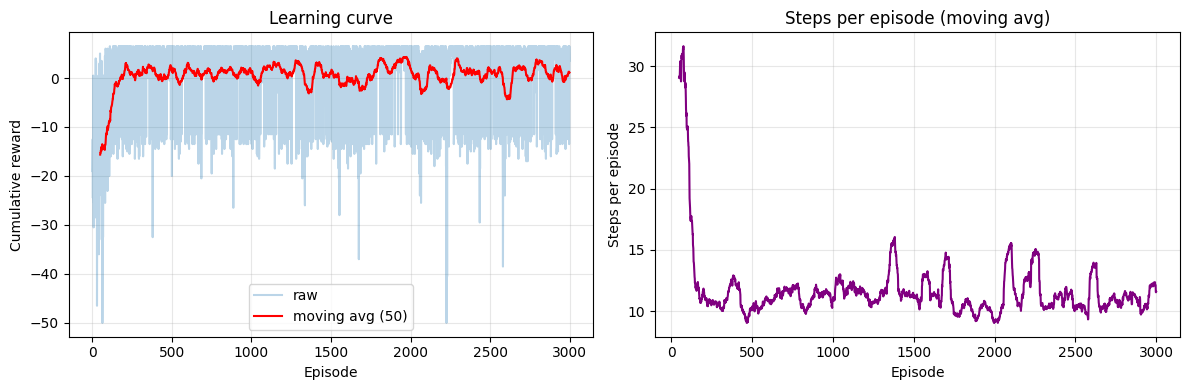

In [12]:
# Learning curve: cumulative reward per episode (moving average to smooth)
def moving_avg(x, w=50):
    return np.convolve(x, np.ones(w) / w, mode='valid')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rewards, alpha=0.3, label='raw')
ax[0].plot(range(49, len(rewards)), moving_avg(rewards), color='red', label='moving avg (50)')
ax[0].set_xlabel('Episode'); ax[0].set_ylabel('Cumulative reward'); ax[0].set_title('Learning curve')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(range(49, len(steps)), moving_avg(steps), color='purple')
ax[1].set_xlabel('Episode'); ax[1].set_ylabel('Steps per episode'); ax[1].set_title('Steps per episode (moving avg)')
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

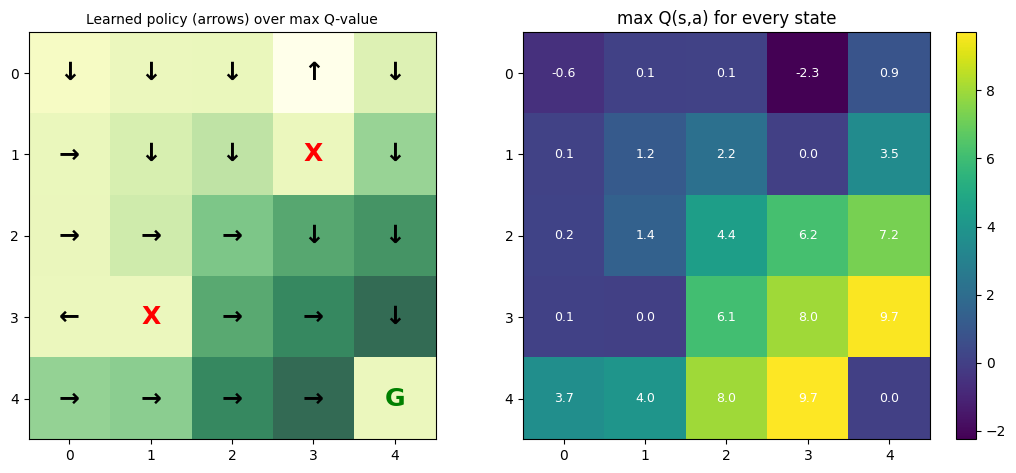

          Up  Down  Left  Right
(0, 0) -0.91 -0.59 -0.95  -0.72
(0, 1) -0.99  0.07 -0.87  -0.81
(0, 2) -1.43  0.11 -1.41  -2.25
(0, 3) -2.25 -3.93 -2.45  -2.61
(0, 4) -1.96  0.85 -1.99  -1.82
(1, 0) -0.69 -0.39 -0.43   0.10


In [13]:
# Visualize the learned Q-values and policy
policy_q = Q.argmax(axis=1)
V_q = Q.max(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
show_policy(env, policy_q, V_q, title='Learned policy (arrows) over max Q-value', ax=ax[0])

im = ax[1].imshow(V_q.reshape(5, 5), cmap='viridis')
for r in range(5):
    for c in range(5):
        ax[1].text(c, r, f"{V_q[env.idx((r, c))]:.1f}", ha='center', va='center', color='white', fontsize=9)
ax[1].set_title('max Q(s,a) for every state'); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

# Q-table for a few states
print(pd.DataFrame(Q[:6], columns=GridWorld.ACTIONS, index=[env.pos(i) for i in range(6)]).round(2))

In [14]:
# Compare Q-learning policy with the optimal policy from value iteration
V_opt, pol_opt = value_iteration(env, gamma=0.9)
non_terminal = [i for i in range(env.n_states) if not env.is_terminal(env.pos(i))]
agree = np.mean([policy_q[i] == pol_opt[i] for i in non_terminal])
print(f"Q-learning policy agrees with optimal policy in {agree*100:.0f}% of states")

Q-learning policy agrees with optimal policy in 82% of states


## Evaluation helper
For Exercise 6 (and the next ones) I need a function that tests the **greedy policy** (no exploration) after training and reports average cumulative reward, average steps and success rate.

In [15]:
def evaluate(env, Q, n_episodes=500, max_steps=100):
    np.random.seed(123)
    rewards, steps, succ = [], [], []
    for _ in range(n_episodes):
        s = env.reset(); total = 0; n = 0; ok = 0
        for _ in range(max_steps):
            a = int(np.argmax(Q[env.idx(s)]))
            s, r, done = env.step(s, a)
            total += r; n += 1
            if done:
                ok = int(s == env.goal); break
        rewards.append(total); steps.append(n); succ.append(ok)
    return np.mean(rewards), np.mean(steps), np.mean(succ) * 100

---
# Exercise 4: Exploration vs. Exploitation

I train with different values of epsilon (alpha = 0.1, gamma = 0.9 fixed) and average over 5 random seeds so that the curves are less noisy.
- epsilon = 0 -> pure exploitation (greedy)
- epsilon = 1 -> pure exploration (random)

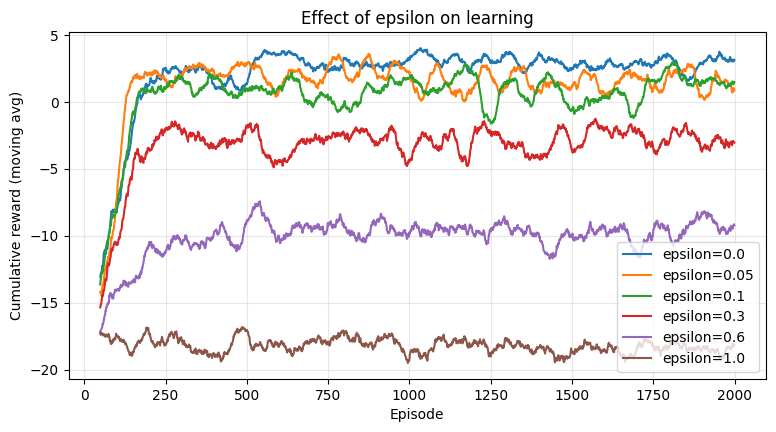

,epsilon,Training reward (last 200 ep),Greedy eval reward,Greedy eval steps,Success rate %
0,0.00,2.80,3.24,9.99,88.68
1,0.05,1.40,1.07,15.13,90.36
2,0.10,1.55,3.13,10.15,88.52
3,0.30,-2.73,3.25,9.59,87.72
4,0.60,-9.15,2.36,11.74,88.68
5,1.00,-18.35,2.49,11.36,88.32


In [16]:
epsilons = [0.0, 0.05, 0.1, 0.3, 0.6, 1.0]
EPISODES = 2000
n_seeds = 5
curves, results4 = {}, []

for eps in epsilons:
    all_r = []; evals = []
    for sd in range(n_seeds):
        Qe, r, st, su = q_learning(env, episodes=EPISODES, epsilon=eps, gamma=0.9, seed=sd)
        all_r.append(r); evals.append(evaluate(env, Qe))
    curves[eps] = np.mean(all_r, axis=0)
    ev = np.mean(evals, axis=0)
    results4.append([eps, curves[eps][-200:].mean(), ev[0], ev[1], ev[2]])

plt.figure(figsize=(9, 4.5))
for eps in epsilons:
    plt.plot(range(49, EPISODES), moving_avg(curves[eps]), label=f'epsilon={eps}')
plt.xlabel('Episode'); plt.ylabel('Cumulative reward (moving avg)')
plt.title('Effect of epsilon on learning'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

df4 = pd.DataFrame(results4, columns=['epsilon', 'Training reward (last 200 ep)',
                                      'Greedy eval reward', 'Greedy eval steps', 'Success rate %'])
df4.round(2)

---
# Exercise 5: Discount Factor

The discount factor gamma decides how much the agent cares about future rewards.
- gamma near 0 -> short-sighted (only immediate reward)
- gamma near 1 -> far-sighted (long-term reward)

I train with different gamma values (epsilon = 0.1, alpha = 0.1) and compare the learned policies.

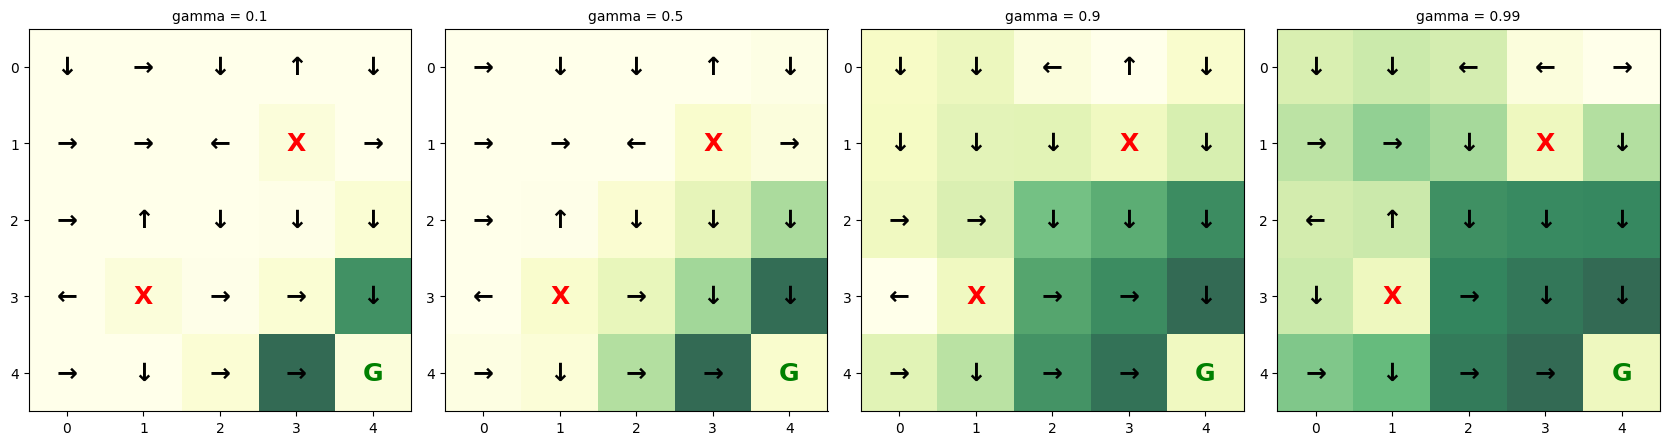

,gamma,Avg reward,Avg steps,Success rate %
0,0.10,-5.67,32.01,98.4
1,0.50,-5.97,32.60,98.4
2,0.90,2.88,10.68,88.6
3,0.99,2.79,10.94,88.8


In [17]:
gammas = [0.1, 0.5, 0.9, 0.99]
fig, axes = plt.subplots(1, len(gammas), figsize=(4.2 * len(gammas), 4.2))
results5, curves5 = [], {}

for ax, g in zip(axes, gammas):
    Qg, r, st, su = q_learning(env, episodes=4000, epsilon=0.1, gamma=g, seed=1)
    curves5[g] = r
    show_policy(env, Qg.argmax(axis=1), Qg.max(axis=1), title=f'gamma = {g}', ax=ax)
    ev = evaluate(env, Qg)
    results5.append([g, *ev])
plt.tight_layout(); plt.show()

df5 = pd.DataFrame(results5, columns=['gamma', 'Avg reward', 'Avg steps', 'Success rate %'])
df5.round(2)

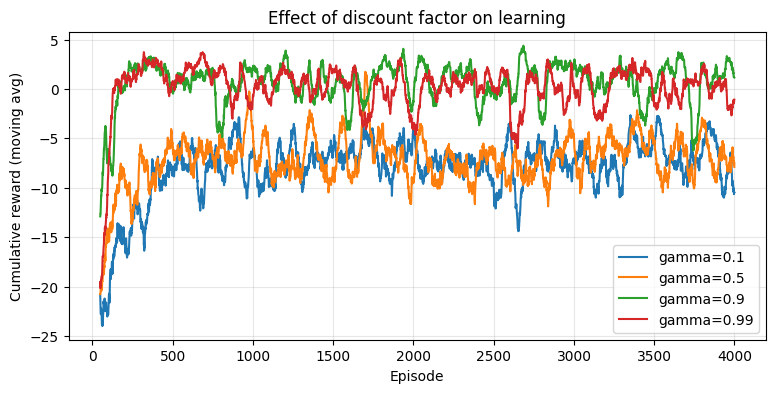

In [18]:
plt.figure(figsize=(9, 4))
for g in gammas:
    plt.plot(range(49, len(curves5[g])), moving_avg(curves5[g]), label=f'gamma={g}')
plt.xlabel('Episode'); plt.ylabel('Cumulative reward (moving avg)')
plt.title('Effect of discount factor on learning'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Observation (Exercise 5):**
- With small gamma (0.1 and 0.5) the agent is short-sighted: the +10 at the goal is discounted so much that it barely matters from far away, while the pit penalty and step penalty are felt immediately. The agent becomes very cautious: it reaches the goal in about 98% of the tests but takes around 31 - 33 steps and has a poor average reward (about -21) because it pays the step penalty for a long time.
- With gamma = 0.9 or 0.99 the agent values the goal properly and takes the short route (about 9 steps, average reward close to -0.7). The price is a higher risk: about 12% of the episodes end in a pit because of slipping on the way.
- Gamma 0.9 and 0.99 give very similar results here. Overall, a larger gamma gives a more far-sighted, goal-directed policy, and a smaller gamma gives a safer but slower one.

---
# Exercise 6: Policy Evaluation

Now I compare different settings (epsilon, gamma, learning rate alpha) using three metrics:
1. **Cumulative reward** (average per episode)
2. **Steps taken** (average per episode)
3. **Success rate** (% of episodes reaching the goal)

Each configuration is trained for 3000 episodes, and the greedy policy is evaluated on 500 test episodes.

In [19]:
configs = {
    'Random policy (eps=1)':       dict(epsilon=1.0, gamma=0.9, alpha=0.1),
    'Greedy (eps=0)':              dict(epsilon=0.0, gamma=0.9, alpha=0.1),
    'Balanced (eps=0.1, g=0.9)':   dict(epsilon=0.1, gamma=0.9, alpha=0.1),
    'Short-sighted (g=0.1)':       dict(epsilon=0.1, gamma=0.1, alpha=0.1),
    'Far-sighted (g=0.99)':        dict(epsilon=0.1, gamma=0.99, alpha=0.1),
    'Low alpha (0.01)':            dict(epsilon=0.1, gamma=0.9, alpha=0.01),
    'High alpha (0.5)':            dict(epsilon=0.1, gamma=0.9, alpha=0.5),
    'Decaying eps (1.0 -> 0.01)':  dict(epsilon=1.0, gamma=0.9, alpha=0.1, epsilon_decay=0.998),
}

rows = []
for name, kw in configs.items():
    r_list = []
    for sd in range(5):
        Qc, r, st, su = q_learning(env, episodes=3000, seed=sd, **kw)
        r_list.append(evaluate(env, Qc))
    m = np.mean(r_list, axis=0)
    rows.append([name, m[0], m[1], m[2]])

df6 = pd.DataFrame(rows, columns=['Setting', 'Avg cumulative reward', 'Avg steps', 'Success rate %'])
df6 = df6.set_index('Setting')
df6.round(2)

,Avg cumulative reward,Avg steps,Success rate %
Setting,,,
Random policy (eps=1),3.21,9.41,87.08
Greedy (eps=0),3.24,9.99,88.68
"Balanced (eps=0.1, g=0.9)",2.69,9.90,85.72
Short-sighted (g=0.1),-5.85,32.33,98.20
Far-sighted (g=0.99),0.97,14.89,89.48
Low alpha (0.01),3.22,9.82,88.16
High alpha (0.5),-14.86,41.92,67.00
Decaying eps (1.0 -> 0.01),3.38,9.85,89.00


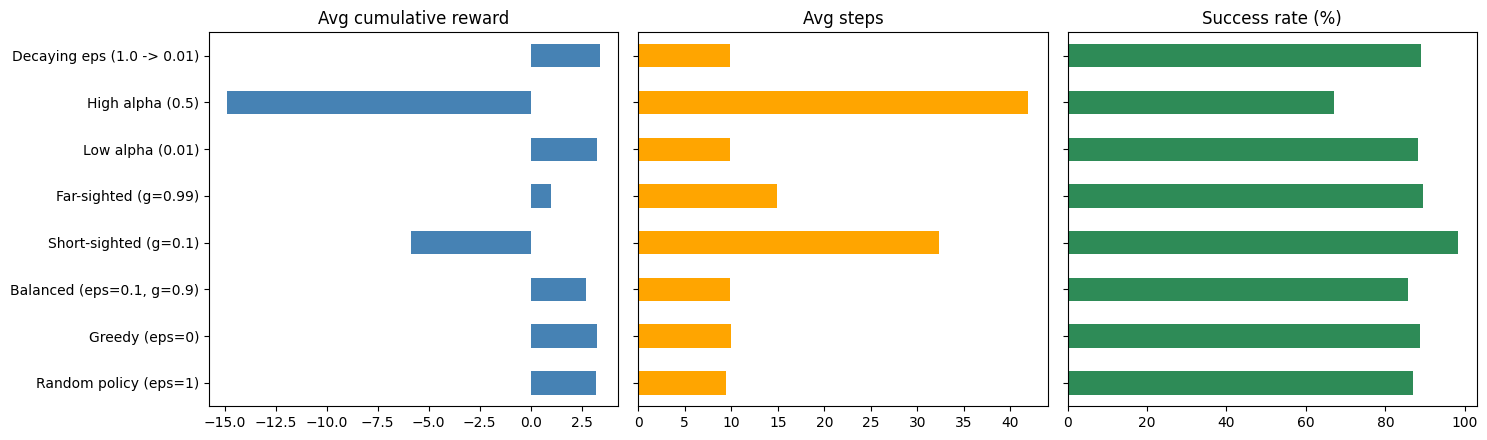

Best setting by cumulative reward: Decaying eps (1.0 -> 0.01)


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
df6['Avg cumulative reward'].plot.barh(ax=ax[0], color='steelblue'); ax[0].set_title('Avg cumulative reward')
df6['Avg steps'].plot.barh(ax=ax[1], color='orange');                 ax[1].set_title('Avg steps')
df6['Success rate %'].plot.barh(ax=ax[2], color='seagreen');          ax[2].set_title('Success rate (%)')
for a in ax[1:]: a.set_yticklabels([])
for a in ax: a.set_ylabel('')
plt.tight_layout(); plt.show()

best = df6['Avg cumulative reward'].idxmax()
print("Best setting by cumulative reward:", best)